In [1]:
from pathlib import Path
import os 

import pandas as pd
import numpy as np
from dotenv import dotenv_values
from matplotlib import pyplot as plt
import seaborn as sns
from matplotlib.patches import Patch
import matplotlib.gridspec as gridspec

plt.rcParams["pdf.fonttype"] = 42

In [ ]:
# Setting up filepaths from config
CONFIG = dotenv_values("config.env") 
DATADIR = Path(CONFIG['DATADIR'])

FLAGS_FP = DATADIR / "7_spatial" / "analyses" / "spatial_flags.csv"

OUTDIR = DATADIR / "publication" / "Fig_02"
os.makedirs(OUTDIR, exist_ok=True)

In [3]:
joined = pd.read_csv(FLAGS_FP,)
joined["is_NN"] = joined.cluster_id.str.contains("NN") 
joined.warning = joined.warning.fillna("None")
joined["clustering"] = joined.cluster_id.apply(lambda x: f"L{x[2]}")

In [4]:
joined

,cluster_id,warning,is_NN,clustering
0,Gb1-2,None,False,L1
1,Gl1-1,None,False,L1
2,NN1-1,None,True,L1
3,NN1-2,None,True,L1
4,NN1-3,None,True,L1
...,...,...,...,...
2005,NN5-5,None,True,L5
2006,NN5-6,None,True,L5
2007,NN5-7,None,True,L5
2008,NN5-8,None,True,L5


/tmp/ipykernel_1390186/490493472.py:24: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  filtered.groupby(['clustering', 'warning'])
/REDACTED-path/HypoMap3D/.venv/lib/python3.11/site-packages/seaborn/axisgrid.py:854: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  func(*plot_args, **plot_kwargs)
/REDACTED-path/HypoMap3D/.venv/lib/python3.11/site-packages/seaborn/axisgrid.py:854: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  func(*plot_args, **plot_kwargs)
/REDACTED-path/HypoMap3D/.venv/lib/python3.11/site-packages/seaborn/axisgr

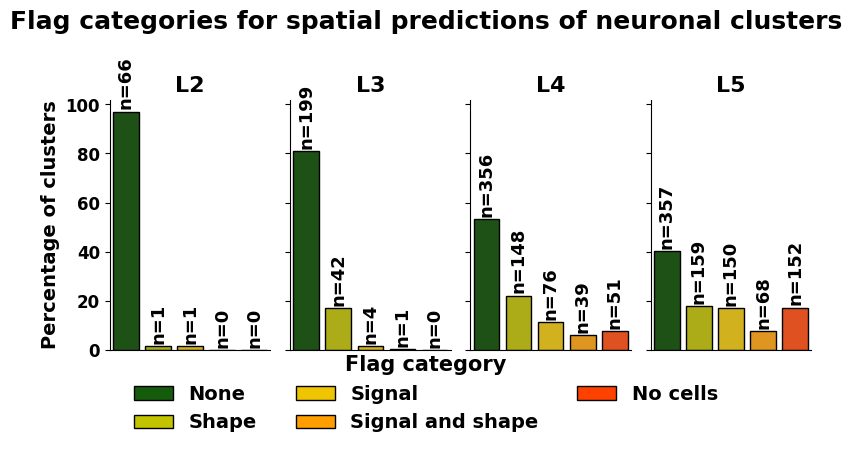

In [5]:

# --- SETTINGS ---
# Define warning order and color mapping
warning_order = ["None", "Shape", "Signal", "Signal and shape", "No cells",]
warning_colors = {
    "None": "#155b0c",
    "Shape": "#C3C400",
    "Signal": "#EFC400",
    "Signal and shape": "#FF9E00",
    "No cells": "#FF4100",
}

# --- DATA PREP ---
# Filter for is_NN == False and desired clustering levels
filtered = joined[
    (joined['is_NN'] == False) & 
    (joined['clustering'].isin(["L2", "L3", "L4", "L5"]))
].copy()

# Ensure 'warning' is a categorical column with defined order
filtered['warning'] = pd.Categorical(filtered['warning'], categories=warning_order, ordered=True)

# Compute count and percentage per clustering and warning
percentage_df = (
    filtered.groupby(['clustering', 'warning'])
    .size()
    .reset_index(name='count')
)

# Compute total rows per clustering group for percentage calculation
totals = percentage_df.groupby('clustering')['count'].transform('sum')
percentage_df['percentage'] = (percentage_df['count'] / totals) * 100

# --- PLOTTING ---
# Create a FacetGrid for the 4 clustering levels
g = sns.FacetGrid(
    data=percentage_df,
    col='clustering',
    col_order=['L2', 'L3', 'L4', 'L5'],
    sharey=True,
    height=5,
    aspect=0.4
)

# Plot the bar plots
g.map_dataframe(
    sns.barplot,
    x='warning',
    y='percentage',
    order=warning_order,
    palette=warning_colors,
    edgecolor='black'
)

# Annotate and style each subplot
for ax, (clustering_level, group_df) in zip(g.axes.flat, percentage_df.groupby('clustering')):
    # Add count annotations
    for warning in warning_order:
        row = group_df[group_df['warning'] == warning]
        if not row.empty:
            y_val = row['percentage'].values[0]
            count = int(row['count'].values[0])
            ax.text(
                x=warning_order.index(warning),
                y=y_val + 1,
                s=f"n={count}",
                ha='center',
                va='bottom',
                fontsize=13,
                fontweight='bold',
                rotation=90
            )

    # Clean up x-axis and y-axis
    ax.set_xlabel('')
    ax.set_xticks([])
    ax.set_ylabel('Percentage of clusters', fontsize=14, fontweight='bold')
    ax.tick_params(axis='y', labelsize=12)
    ax.set_title(f"{clustering_level}", fontsize=16, fontweight='bold')
    
    for label in ax.get_yticklabels():
        label.set_fontweight('bold')

    sns.despine(ax=ax)

# Remove x-axis label globally
g.set_axis_labels("", "Percentage of clusters")

# --- SUPER TITLE ---
g.fig.suptitle(
    "Flag categories for spatial predictions of neuronal clusters",
    fontsize=18,
    fontweight='bold'
)

# Adjust layout to make room for legend and title
plt.tight_layout()
plt.subplots_adjust(top=0.8, bottom=0.3)

# --- LEGEND ---
# Create custom legend handles
legend_elements = [
    Patch(facecolor=warning_colors[label], edgecolor='black', label=label)
    for label in warning_order
]

# Add legend to the figure (centered below all subplots)
legend = g.fig.legend(
    handles=legend_elements,
    loc='lower center',
    ncol=3,
    frameon=False,
    title='Flag category',
    fontsize=14,
    title_fontsize=15,
    bbox_to_anchor=(0.5, 0.1)
)

# Make legend title and text bold
for text in legend.get_texts():
    text.set_fontweight('bold')
legend.get_title().set_fontweight('bold')

# --- OPTIONAL: Save to file ---
g.fig.savefig(OUTDIR / "warning_categories_by_clustering_N.pdf", dpi=300, bbox_inches='tight')

# Show the plot
plt.show()
